# REGRESIÓN LINEAL SIMPLE Y MÚLTIPLE - CENSO 2024

**Pregunta:** ¿qué características de la vivienda se asocian con que un municipio de Bolivia tenga un Índice de Precariedad de Servicios (IPS) más alto, y con qué error se puede estimar ese índice?

**Variable objetivo:** `ips`, el porcentaje de viviendas de cada municipio con dos o más carencias entre agua, saneamiento, electricidad e internet. El IPS y la clase `vivienda_precaria` son **definiciones operativas del proyecto**, no indicadores oficiales del INE.

**Por qué se cambia de vivienda a municipio:** la regresión lineal necesita una respuesta continua. En la vivienda, `vivienda_precaria` solo vale 0 o 1 y `n_carencias` solo va de 0 a 4. Al agregar por municipio, el IPS toma valores continuos y sigue la misma definición usada en los modelos de clasificación. Por eso, cada fila de este análisis es un **municipio**, no una vivienda.

## Concepto básico

La regresión lineal modela una variable dependiente continua a partir de una o varias variables independientes:

$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_n X_n + \varepsilon$$

donde $Y$ es el objetivo (aquí, el IPS), $\beta_0$ es el intercepto, cada $\beta_i$ es el coeficiente de una variable y $\varepsilon$ es el error aleatorio. OLS elige los coeficientes que minimizan la suma de los errores al cuadrado.

- **Signo de $\beta_i$:** positivo si el objetivo tiende a subir cuando sube la variable; negativo si tiende a bajar.
- **Magnitud de $\beta_i$:** cambio esperado en el objetivo por cada unidad adicional de la variable, manteniendo constantes las demás.
- **p-valor:** contrasta $H_0: \beta_i = 0$. Si $p \leq 0.05$ se rechaza $H_0$ y el coeficiente se considera significativo.

## Medidas de ajuste

- **R²:** proporción de la variación de $Y$ que explica el modelo. El R² ajustado además penaliza el número de variables.
- **MSE:** promedio de los errores al cuadrado; castiga más los errores grandes.
- **RMSE:** raíz del MSE; queda en las mismas unidades del objetivo (puntos del IPS).
- **MAE:** promedio de los errores absolutos; es menos sensible a valores extremos.
- **AIC/BIC:** comparan modelos con la misma respuesta y penalizan la complejidad.

## Ventajas y desventajas

La regresión lineal es fácil de interpretar y cuantifica la asociación de cada variable. A cambio, supone una relación lineal, es sensible a la multicolinealidad y a los valores extremos, y no captura relaciones no lineales sin transformaciones.

# 1. LIBRERÍAS Y FUNCIONES

In [1]:
# Cargamos librerías
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# modelo de regresión lineal
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor

# train test y métricas
from sklearn.model_selection import train_test_split, KFold, LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"font.size":10, "axes.titlesize":13, "figure.dpi":115})
COLOR = "#237b86"       # mismo tono de los notebooks anteriores del proyecto
REFERENCIA = "#d1843d"  # línea de tendencia o de referencia
FUENTE = "Fuente: elaboración propia con microdatos del Censo 2024, INE Bolivia."

def rmse(real, predicho):
    # raíz del error cuadrático medio: queda en puntos porcentuales del IPS
    return float(np.sqrt(mean_squared_error(real, predicho)))

def logit(ips):
    # lleva el IPS (0 a 100) a la escala log-odds
    p = ips / 100
    return np.log(p / (1 - p))

def logit_inversa(z):
    # regresa la predicción a porcentaje; el resultado siempre queda entre 0 y 100
    return 100 * np.exp(z) / (1 + np.exp(z))

def pruebas_supuestos(modelo):
    # pruebas de la sección 4.3; cada una devuelve su p-valor
    exog = modelo.model.data.orig_exog
    ordenado = exog.sort_index()  # orden por código territorial para medir dependencia entre vecinos
    respuesta = pd.Series(modelo.model.endog, index=exog.index).loc[ordenado.index]
    modelo_ordenado = sm.OLS(respuesta, ordenado).fit()
    return pd.Series({
        "Jarque-Bera (normalidad)": sms.jarque_bera(modelo.resid)[1],
        "Breusch-Pagan (homocedasticidad)": sms.het_breuschpagan(modelo.resid, modelo.model.exog)[3],
        "RESET (forma lineal)": float(linear_reset(modelo, power=2, use_f=True).pvalue),
        "Breusch-Godfrey (autocorrelación)": acorr_breusch_godfrey(modelo_ordenado, nlags=1)[1],
    }), float(sms.durbin_watson(modelo_ordenado.resid))

# 2. PARAMETRIZACIÓN

In [2]:
# rutas: se busca el CSV en data/ y, si no está, en la carpeta local donde se guardó
DATA = Path("data")
CSV = DATA / "Vivienda_CPV-2024.csv"
if not CSV.is_file():
    CSV = Path.home() / "Desktop" / "Base de datos CSV" / "Vivienda_CPV-2024.csv"
assert CSV.is_file(), "Copiar Vivienda_CPV-2024.csv a la carpeta data/."

RANDOM_STATE = 42    # misma semilla de los modelos anteriores del proyecto
TEST_SIZE = 0.20     # 80 % entrenamiento, 20 % prueba
ALFA = 0.05          # nivel de significancia
VIF_MAXIMO = 10      # VIF >= 10: multicolinealidad severa
TOLERANCIA_RMSE = 0.10  # diferencia en puntos del IPS que se considera un empate

DEPARTAMENTOS = {"01":"Chuquisaca", "02":"La Paz", "03":"Cochabamba", "04":"Oruro", "05":"Potosí",
                 "06":"Tarija", "07":"Santa Cruz", "08":"Beni", "09":"Pando"}

territorio = ["idep", "iprov", "imun"]
filtros = ["v01_tipoviv", "v02_condocup", "tot_pers"]
fuentes_objetivo = ["v07_aguapro", "v15_servsan", "v16_desague", "v09_energia", "v19e_f"]
caracteristicas = ["urbrur", "v03_pared", "v05_techo", "v06_piso", "v11_basura", "v14_dormit", "v17_tenencia", "tip_hog"]

# 3. DATOS

Se reproducen la población analítica y las reglas de carencia de `entendimiento de datos.ipynb`: viviendas particulares de tipos 1 a 6, ocupadas con personas presentes y con al menos una persona. Los controles con `assert` comprueban que las cifras coinciden con los notebooks anteriores.

In [3]:
# cargamos solo las columnas necesarias; todas como texto categórico para ahorrar memoria
columnas_lectura = list(dict.fromkeys(territorio + filtros + fuentes_objetivo + caracteristicas))
censo = pd.read_csv(CSV, sep=";", encoding="utf-8-sig", usecols=columnas_lectura,
                    dtype={c:"category" for c in columnas_lectura})
assert len(censo) == 4_490_488, "El número de filas originales cambió."

# misma población analítica de los notebooks anteriores
particular = censo["v01_tipoviv"].astype("string").isin({"1","2","3","4","5","6"})
presente = censo["v02_condocup"].astype("string").isin({"0","1"})
con_personas = pd.to_numeric(censo["tot_pers"].astype("string"), errors="coerce").gt(0)
aplica = censo[["v07_aguapro","v15_servsan","v09_energia","v19e_f"]].notna().all(axis=1)
viviendas = censo.loc[particular & presente & con_personas & aplica].copy()
assert len(viviendas) == 3_623_711, "La población analítica no coincide con el análisis previo."
print("CSV original:", censo.shape)
print("Viviendas analíticas:", viviendas.shape)

del censo, particular, presente, con_personas, aplica
_ = gc.collect()

CSV original: (4490488, 19)
Viviendas analíticas: (3623711, 19)


In [4]:
# reglas de carencia documentadas en entendimiento de datos.ipynb
def indicador(index, reglas):
    resultado = pd.Series(pd.NA, index=index, dtype="Int8")
    for condicion, valor in reglas:
        resultado.loc[condicion.fillna(False)] = valor
    return resultado

agua = viviendas["v07_aguapro"].astype("string")
san = viviendas["v15_servsan"].astype("string")
des = viviendas["v16_desague"].astype("string")
elec = viviendas["v09_energia"].astype("string")
inet = viviendas["v19e_f"].astype("string")
carencias = pd.DataFrame({
    "agua": indicador(viviendas.index, [(agua.isin({"1","2","4","6"}),0), (agua.isin({"5","7"}),1)]),
    "saneamiento": indicador(viviendas.index, [((san=="1") & des.isin({"1","2","6"}),0),
                                               (san.isin({"2","3"}) | ((san=="1") & (des=="5")),1)]),
    "electricidad": indicador(viviendas.index, [(elec.isin({"1","2","3","4"}),0), (elec=="5",1)]),
    "internet": indicador(viviendas.index, [(inet=="1",0), (inet=="2",1)]),
})
completas = carencias.notna().all(axis=1)

# código único del municipio: departamento + provincia + municipio
viviendas["municipio"] = (viviendas["idep"].astype("string") + viviendas["iprov"].astype("string")
                          + viviendas["imun"].astype("string"))
analiticas_por_municipio = viviendas.groupby("municipio").size()

clasificables = viviendas.loc[completas].copy()
clasificables["precaria"] = (carencias.loc[completas].sum(axis=1) >= 2).astype("int8").to_numpy()
assert len(clasificables) == 2_635_157, "La población con objetivo cambió."
ips_nacional = 100 * clasificables["precaria"].mean()
assert round(ips_nacional, 2) == 19.60, "El IPS no coincide con el notebook de entendimiento."
print("Viviendas clasificables:", len(clasificables), "| IPS nacional:", round(ips_nacional, 2), "%")

del viviendas, carencias, completas, agua, san, des, elec, inet
_ = gc.collect()

Viviendas clasificables: 2635157 | IPS nacional: 19.6 %


Las respuestas que no permiten clasificar alguna carencia quedan fuera del IPS y no se convierten de forma arbitraria en acceso o falta de acceso. Tanto el IPS como las variables explicativas se calculan sobre esas mismas viviendas clasificables.

In [5]:
# de vivienda a municipio: cada fila nueva resume las viviendas clasificables de un municipio
grupo = clasificables["municipio"].astype("string").to_numpy()

def porcentaje(columna, codigos):
    # porcentaje de viviendas del municipio cuya respuesta está en los códigos indicados
    marca = clasificables[columna].astype("string").isin(codigos).to_numpy(dtype=float)
    return 100 * pd.Series(marca).groupby(grupo).mean()

personas = pd.to_numeric(clasificables["tot_pers"].astype("string")).to_numpy(dtype=float)
municipios = pd.DataFrame({
    "ips": 100 * pd.Series(clasificables["precaria"].to_numpy(dtype=float)).groupby(grupo).mean(),
    "n_viviendas": pd.Series(grupo).groupby(grupo).size(),
    "pct_rural": porcentaje("urbrur", {"2"}),
    "pct_piso_tierra": porcentaje("v06_piso", {"1"}),
    "pct_pared_no_ladrillo": porcentaje("v03_pared", {"2","3","4","5","6","7"}),
    "pct_techo_paja": porcentaje("v05_techo", {"4"}),
    "pct_basura_sin_servicio": porcentaje("v11_basura", {"3","4","5","6","7"}),
    "pct_hasta_un_dormitorio": porcentaje("v14_dormit", {"0","1"}),
    "pct_alquiler_anticretico": porcentaje("v17_tenencia", {"4","5","6"}),
    "pct_unipersonal": porcentaje("tip_hog", {"1"}),
    "personas_vivienda": pd.Series(personas).groupby(grupo).mean(),
})
municipios["log_viviendas"] = np.log(municipios["n_viviendas"])
municipios["cobertura"] = 100 * municipios["n_viviendas"] / analiticas_por_municipio
municipios["departamento"] = municipios.index.str[:2].map(DEPARTAMENTOS)
municipios["provincia"] = municipios.index.str[:4]
municipios.index.name = "municipio"
municipios = municipios.sort_index()

assert len(municipios) == 343 and municipios.notna().all().all()
assert municipios["n_viviendas"].sum() == len(clasificables)
assert municipios["ips"].between(0, 100, inclusive="neither").all()  # requisito del logit en 4.4
del clasificables, grupo, personas
_ = gc.collect()

print(municipios.shape)
municipios.head(2)

(343, 15)


,ips,n_viviendas,pct_rural,pct_piso_tierra,pct_pared_no_ladrillo,pct_techo_paja,pct_basura_sin_servicio,pct_hasta_un_dormitorio,pct_alquiler_anticretico,pct_unipersonal,personas_vivienda,log_viviendas,cobertura,departamento,provincia
municipio,,,,,,,,,,,,,,,
010101,6.132633,82966,5.19731,4.838126,14.731336,0.871441,11.433599,40.117639,29.407227,22.276595,3.144469,11.326186,89.662924,Chuquisaca,0101
010102,25.226313,1657,100.00000,13.578757,45.624623,1.750151,66.264333,49.849125,6.336753,29.873265,2.915510,7.412764,54.221204,Chuquisaca,0101


**Detalle de las variables** (una fila por municipio, códigos según la hoja `VIVIENDA` del diccionario oficial)

| Variable | Definición | Origen |
|---|---|---|
| `ips` | **Objetivo.** % de viviendas con dos o más carencias | agua, saneamiento, electricidad e internet |
| `pct_rural` | % de viviendas en área rural | `urbrur` = 2 |
| `pct_piso_tierra` | % con piso de tierra | `v06_piso` = 1 |
| `pct_pared_no_ladrillo` | % con paredes que no son de ladrillo, bloque u hormigón | `v03_pared` = 2 a 7 |
| `pct_techo_paja` | % con techo de paja, palma, caña o barro | `v05_techo` = 4 |
| `pct_basura_sin_servicio` | % que bota, quema o entierra la basura, o la elimina de otra forma, sin contenedor ni carro basurero | `v11_basura` = 3 a 7 |
| `pct_hasta_un_dormitorio` | % con cero o un dormitorio | `v14_dormit` = 0 o 1 |
| `pct_alquiler_anticretico` | % en alquiler, anticrético o contrato mixto | `v17_tenencia` = 4 a 6 |
| `pct_unipersonal` | % de hogares unipersonales | `tip_hog` = 1 |
| `personas_vivienda` | Promedio de personas por vivienda | `tot_pers` |
| `log_viviendas` | Logaritmo del número de viviendas clasificables | conteo por municipio |

**Sin fuga de información:** ninguna variable explicativa usa las preguntas que definen las carencias (`v07`, `v15`, `v16`, `v09`, `v19e_f`). Tampoco se usan bienes ni servicios cercanos a ellas (`v18`, `v19`). Los códigos territoriales no entran como predictores; `departamento` y `provincia` solo sirven para describir y validar.

`n_viviendas` y `cobertura` (% de viviendas analíticas del municipio cuya clase pudo determinarse) también se usan solo para describir y revisar errores.

# 4. PROCESO

## 4.1. EDA - Análisis exploratorio de datos

In [6]:
# tipo de datos
municipios.dtypes

ips                         float64
n_viviendas                   int64
pct_rural                   float64
pct_piso_tierra             float64
pct_pared_no_ladrillo       float64
pct_techo_paja              float64
pct_basura_sin_servicio     float64
pct_hasta_un_dormitorio     float64
pct_alquiler_anticretico    float64
pct_unipersonal             float64
personas_vivienda           float64
log_viviendas               float64
cobertura                   float64
departamento                    str
provincia                       str
dtype: object

In [7]:
predictoras = ["pct_rural", "pct_piso_tierra", "pct_pared_no_ladrillo", "pct_techo_paja", "pct_basura_sin_servicio",
               "pct_hasta_un_dormitorio", "pct_alquiler_anticretico", "pct_unipersonal", "personas_vivienda", "log_viviendas"]
municipios[["ips"] + predictoras + ["n_viviendas", "cobertura"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ips,343.0,42.36,21.22,2.68,25.10,42.04,59.61,95.42
pct_rural,343.0,71.08,32.97,0.00,44.50,83.64,100.00,100.00
pct_piso_tierra,343.0,41.20,22.71,1.58,22.53,39.89,59.47,89.97
pct_pared_no_ladrillo,343.0,57.72,24.32,2.46,41.41,62.82,77.43,93.52
pct_techo_paja,343.0,12.62,13.06,0.11,2.75,8.48,19.14,72.26
pct_basura_sin_servicio,343.0,66.27,27.24,0.90,48.59,72.96,90.52,99.77
pct_hasta_un_dormitorio,343.0,61.63,12.73,30.40,52.54,63.20,71.23,92.60
pct_alquiler_anticretico,343.0,8.70,8.06,0.00,2.25,5.87,13.19,39.10
pct_unipersonal,343.0,30.11,10.32,3.09,21.86,30.46,38.28,53.40
personas_vivienda,343.0,3.00,0.61,1.94,2.54,2.87,3.40,6.11


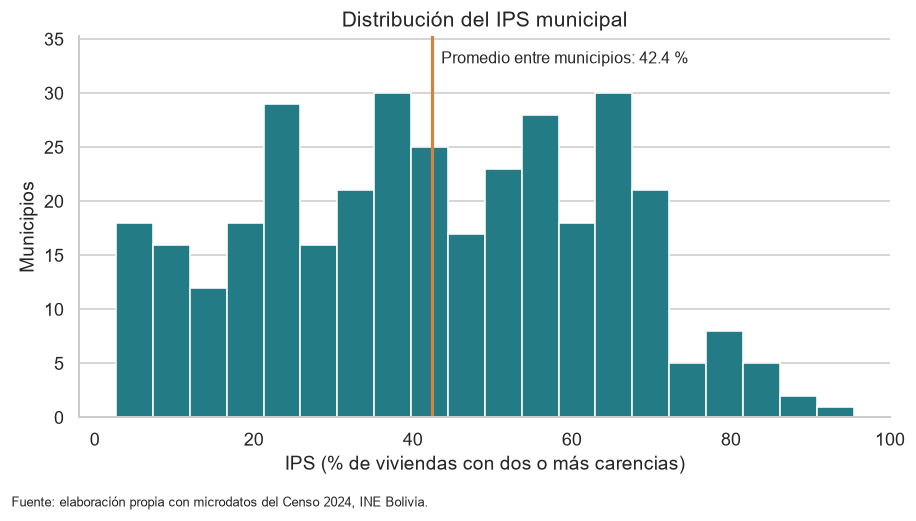

IPS nacional (cada vivienda pesa igual): 19.6 %
Promedio de los IPS municipales (cada municipio pesa igual): 42.36 %


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(municipios["ips"], bins=20, color=COLOR, edgecolor="white")
ax.axvline(municipios["ips"].mean(), color=REFERENCIA, linewidth=2)
ax.annotate(f"Promedio entre municipios: {municipios['ips'].mean():.1f} %",
            (municipios["ips"].mean(), ax.get_ylim()[1]*1.04), xytext=(6, 0), textcoords="offset points")
ax.set_ylim(0, ax.get_ylim()[1]*1.12)  # espacio libre para la anotación
ax.set(title="Distribución del IPS municipal", xlabel="IPS (% de viviendas con dos o más carencias)",
       ylabel="Municipios")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(False, axis="x")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
print("IPS nacional (cada vivienda pesa igual):", round(ips_nacional, 2), "%")
print("Promedio de los IPS municipales (cada municipio pesa igual):", round(municipios["ips"].mean(), 2), "%")

**Lectura:** el IPS municipal va de 2,68 % a 95,42 %, con mucha variación que explicar. El promedio entre municipios (42,36 %) es más del doble del IPS nacional (19,60 %), y las dos cifras son correctas: en el nacional pesa cada vivienda, por lo que dominan las ciudades grandes con pocas carencias; aquí cada municipio pesa lo mismo, tenga 117 o 379.706 viviendas clasificables. **Los resultados de este notebook describen municipios, no viviendas.**

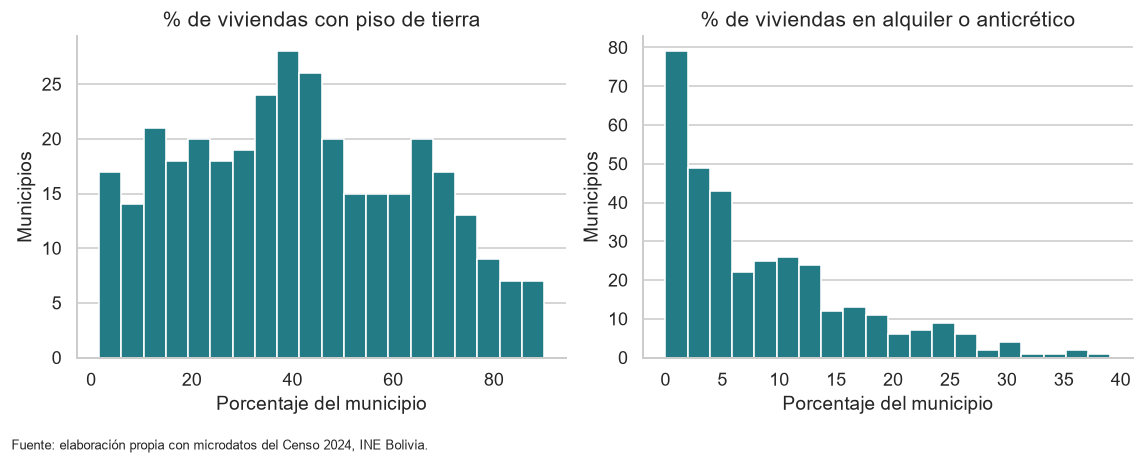

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, columna, titulo in [(axes[0], "pct_piso_tierra", "% de viviendas con piso de tierra"),
                            (axes[1], "pct_alquiler_anticretico", "% de viviendas en alquiler o anticrético")]:
    ax.hist(municipios[columna], bins=20, color=COLOR, edgecolor="white")
    ax.set(title=titulo, xlabel="Porcentaje del municipio", ylabel="Municipios")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False, axis="x")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

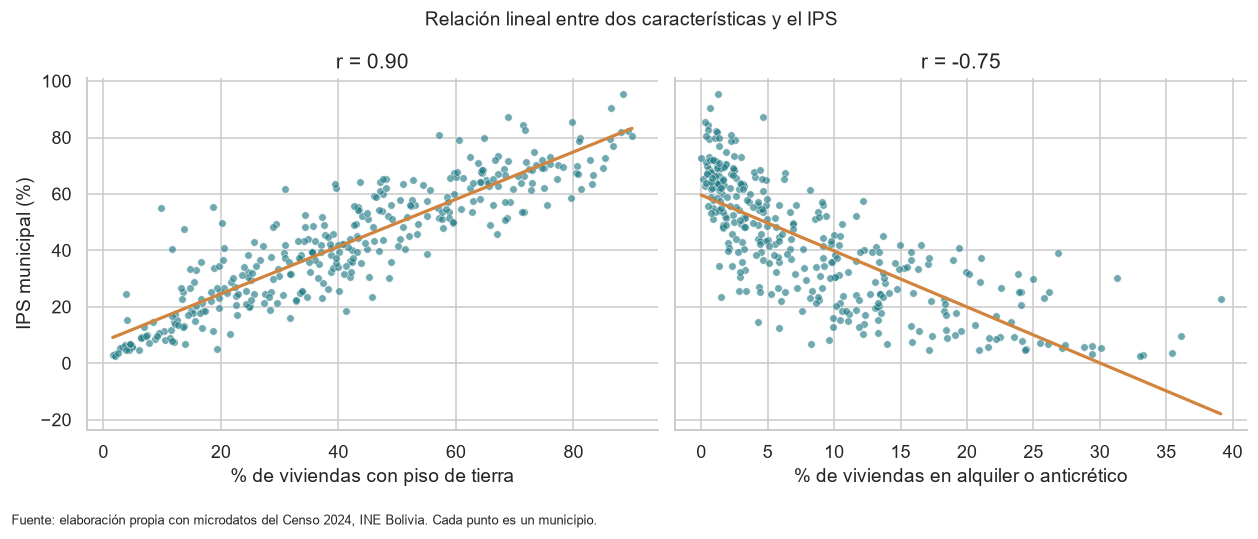

In [10]:
# gráficos de dispersión con su línea de regresión
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, columna, etiqueta in [(axes[0], "pct_piso_tierra", "% de viviendas con piso de tierra"),
                              (axes[1], "pct_alquiler_anticretico", "% de viviendas en alquiler o anticrético")]:
    ax.scatter(municipios[columna], municipios["ips"], s=22, alpha=0.65, color=COLOR, edgecolor="white", linewidth=0.4)
    pendiente, intercepto = np.polyfit(municipios[columna], municipios["ips"], 1)
    extremos = np.array([municipios[columna].min(), municipios[columna].max()])
    ax.plot(extremos, pendiente * extremos + intercepto, color=REFERENCIA, linewidth=2)
    ax.set(title=f"r = {municipios[columna].corr(municipios['ips']):.2f}", xlabel=etiqueta)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("IPS municipal (%)")
fig.suptitle("Relación lineal entre dos características y el IPS")
fig.text(0.01, 0.01, FUENTE + " Cada punto es un municipio.", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Lectura:** hay una relación lineal clara y positiva con el piso de tierra, y negativa con el alquiler o anticrético. En el segundo caso, la recta baja de 0 % a partir de cerca de 30 % de alquiler, un valor imposible para un porcentaje: es una primera señal de que una recta simple no sirve en todo el rango.

Estos gráficos son descriptivos: las decisiones del modelo se toman más abajo, solo con entrenamiento.

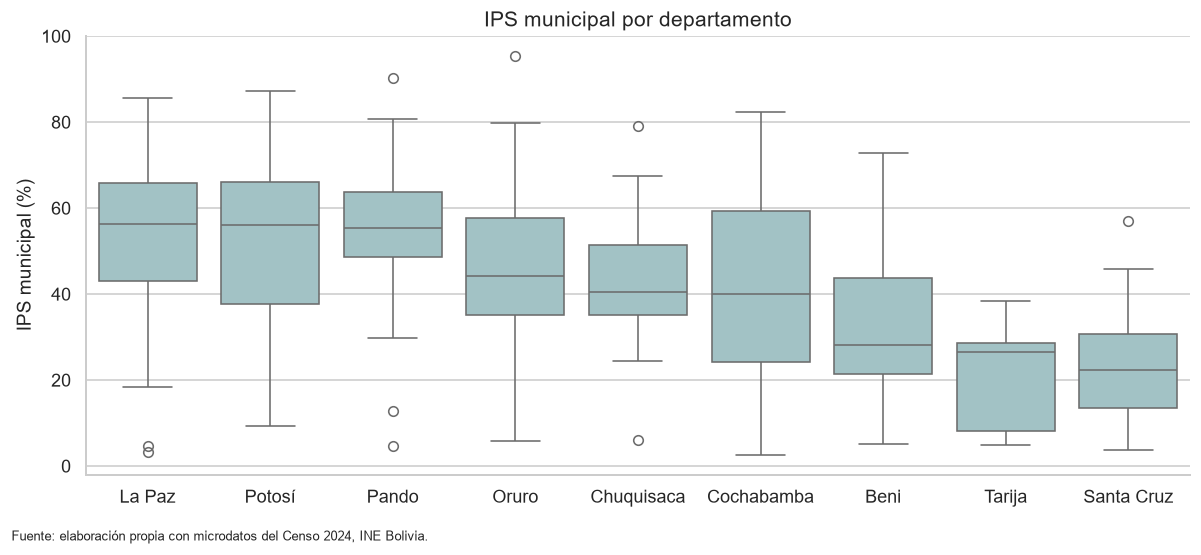

,municipios,ips_mediana,viviendas
departamento,,,
La Paz,87,56.2,825886
Potosí,42,56.2,245879
Pando,15,55.3,18149
Oruro,35,44.2,161294
Chuquisaca,29,40.4,149146
Cochabamba,48,40.1,451436
Beni,20,28.3,67092
Tarija,11,26.5,112394
Santa Cruz,56,22.4,603881


In [11]:
# boxplot del IPS por departamento, ordenado por mediana
orden = municipios.groupby("departamento")["ips"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.boxplot(data=municipios, x="departamento", y="ips", order=orden, color="#9cc7cb", linewidth=1, ax=ax)
ax.set(title="IPS municipal por departamento", xlabel="", ylabel="IPS municipal (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(False, axis="x")
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
display(municipios.groupby("departamento").agg(municipios=("ips","size"), ips_mediana=("ips","median"),
        viviendas=("n_viviendas","sum")).sort_values("ips_mediana", ascending=False).round(1))

**Lectura:** La Paz y Potosí tienen las medianas más altas (56,2 %) y Santa Cruz la más baja (22,4 %), con mucha dispersión dentro de cada departamento. Pando tiene solo 15 municipios y 18.149 viviendas clasificables, por lo que sus resultados deben leerse con más cuidado.

## 4.2. Modelo de Regresión

La división es aleatoria, 80/20, con la misma semilla de los modelos anteriores. Los municipios de prueba no intervienen en la selección de variables ni en la elección del modelo.

In [12]:
# Definir las variables independientes y la dependiente
X = municipios[predictoras]
y = municipios["ips"]  # variable dependiente

# Añadir una constante a las variables independientes (intercepto)
X = sm.add_constant(X)

# División en entrenamiento y prueba: prueba queda reservada hasta el final
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert x_train.index.intersection(x_test.index).empty
print(X.shape)
print(x_train.shape)  # el modelo entrena
print(x_test.shape)   # evaluamos al modelo
X.head(2)

(343, 11)
(274, 11)
(69, 11)


,const,pct_rural,pct_piso_tierra,pct_pared_no_ladrillo,pct_techo_paja,pct_basura_sin_servicio,pct_hasta_un_dormitorio,pct_alquiler_anticretico,pct_unipersonal,personas_vivienda,log_viviendas
municipio,,,,,,,,,,,
010101,1.0,5.19731,4.838126,14.731336,0.871441,11.433599,40.117639,29.407227,22.276595,3.144469,11.326186
010102,1.0,100.00000,13.578757,45.624623,1.750151,66.264333,49.849125,6.336753,29.873265,2.915510,7.412764


### Regresión lineal simple

In [13]:
# correlación de cada variable con el IPS: solo con entrenamiento
correlaciones = x_train[predictoras].corrwith(y_train).sort_values(key=np.abs, ascending=False)
variable_simple = correlaciones.index[0]
display(correlaciones.round(3).to_frame("r con el IPS (entrenamiento)"))
print("Variable para la regresión simple:", variable_simple)

,r con el IPS (entrenamiento)
pct_piso_tierra,0.886
pct_pared_no_ladrillo,0.864
pct_hasta_un_dormitorio,0.835
pct_basura_sin_servicio,0.817
pct_rural,0.758
pct_alquiler_anticretico,-0.752
pct_techo_paja,0.635
pct_unipersonal,0.552
personas_vivienda,-0.407
log_viviendas,-0.289


Variable para la regresión simple: pct_piso_tierra


In [14]:
# regresión lineal simple con fórmula
df_train = pd.concat([x_train, y_train], axis=1)
modelo_simple = smf.ols(f"ips ~ {variable_simple}", data=df_train).fit()
print(modelo_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                    ips   R-squared:                       0.785
Model:                            OLS   Adj. R-squared:                  0.785
Method:                 Least Squares   F-statistic:                     995.5
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           6.88e-93
Time:                        17:05:21   Log-Likelihood:                -1011.7
No. Observations:                 274   AIC:                             2027.
Df Residuals:                     272   BIC:                             2035.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           8.3305      1.229     

**Interpretación:** el modelo estimado es $IPS = 8{,}33 + 0{,}82 \cdot pct\_piso\_tierra$. Cada punto porcentual adicional de viviendas con piso de tierra se asocia, en promedio, con 0,82 puntos más de IPS. El intercepto (8,33) es el IPS esperado con 0 % de piso de tierra. El p-valor es menor a 0,05 y el R² indica que esta sola variable explica 78,5 % de la variación en entrenamiento.

### Regresión lineal múltiple

In [15]:
# regresión lineal múltiple con todas las variables candidatas
modelo_completo = sm.OLS(y_train, x_train).fit()
print(modelo_completo.summary())

                            OLS Regression Results                            
Dep. Variable:                    ips   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.915
Method:                 Least Squares   F-statistic:                     294.6
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          1.33e-136
Time:                        17:05:21   Log-Likelihood:                -879.82
No. Observations:                 274   AIC:                             1782.
Df Residuals:                     263   BIC:                             1821.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

**Interpretación:** el R² ajustado sube de 0,785 a 0,915, y varios coeficientes dejan de ser significativos. Es el caso de `pct_rural` (p=0,232), aunque por sí solo tiene una correlación alta con el IPS (r=0,758). Eso no significa que el área rural no importe: lo que aporta ya está recogido por otras variables correlacionadas con ella, como el piso de tierra, el manejo de basura o el alquiler. El aviso de número de condición alto en el resumen apunta a esa multicolinealidad, y por eso se revisa a continuación.

In [16]:
# *** Evaluando multicolinealidad: VIF ***
# VIF >= 10: multicolinealidad severa | VIF >= 5: elevada | VIF < 5: débil a moderada
def tabla_vif(datos):
    columnas = [c for c in datos.columns if c != "const"]
    return pd.DataFrame({"Variable": columnas,
                         "VIF": [variance_inflation_factor(datos.values, list(datos.columns).index(c)) for c in columnas]
                        }).sort_values("VIF", ascending=False)

# se retira una variable a la vez, la de mayor VIF, hasta que ninguna llegue al máximo
variables = list(predictoras)
vif_inicial = tabla_vif(x_train[["const"] + variables])
retiradas_vif = []
while True:
    actual = tabla_vif(x_train[["const"] + variables])
    if actual["VIF"].iloc[0] < VIF_MAXIMO:
        break
    retiradas_vif.append(actual["Variable"].iloc[0])
    variables.remove(actual["Variable"].iloc[0])
display(vif_inicial.round(2))
print("Retiradas por VIF:", retiradas_vif)

,Variable,VIF
7,pct_unipersonal,10.73
8,personas_vivienda,10.20
2,pct_pared_no_ladrillo,5.59
4,pct_basura_sin_servicio,4.93
1,pct_piso_tierra,4.56
0,pct_rural,4.52
5,pct_hasta_un_dormitorio,3.80
6,pct_alquiler_anticretico,3.49
9,log_viviendas,2.04
3,pct_techo_paja,1.92


Retiradas por VIF: ['pct_unipersonal']


**Interpretación:** `pct_unipersonal` y `personas_vivienda` superan el VIF de 10, porque miden casi lo mismo: a más hogares de una persona, menos personas por vivienda (r=-0,92 en los 343 municipios). Al retirar la primera, ninguna otra variable llega a ese límite.

A continuación se aplica la eliminación hacia atrás con las hipótesis del modelo:

- $H_0: \beta_i = 0$, la variable $X_i$ no aporta a la explicación de $Y$.
- $H_1: \beta_i \neq 0$.
- Si $p \leq 0.05$, se rechaza $H_0$ y la variable se mantiene.

In [17]:
# eliminación hacia atrás: H0: B_i=0 | H1: B_i!=0
# si p_valor<=alfa se rechaza H0; si no, se retira la variable con mayor p-valor y se reajusta
pasos = []
while True:
    ajuste = sm.OLS(y_train, x_train[["const"] + variables]).fit()
    p_valores = ajuste.pvalues.drop("const")
    if p_valores.max() <= ALFA:
        break
    pasos.append({"Variable retirada": p_valores.idxmax(), "p-valor": p_valores.max()})
    variables.remove(p_valores.idxmax())
modelo_reducido = ajuste
display(pd.DataFrame(pasos).round(4))
print("Variables finales:", variables)
print(modelo_reducido.summary())

,Variable retirada,p-valor
0,personas_vivienda,0.8061
1,pct_rural,0.2972
2,log_viviendas,0.0616


Variables finales: ['pct_piso_tierra', 'pct_pared_no_ladrillo', 'pct_techo_paja', 'pct_basura_sin_servicio', 'pct_hasta_un_dormitorio', 'pct_alquiler_anticretico']
                            OLS Regression Results                            
Dep. Variable:                    ips   R-squared:                       0.916
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     485.4
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          1.83e-140
Time:                        17:05:21   Log-Likelihood:                -883.15
No. Observations:                 274   AIC:                             1780.
Df Residuals:                     267   BIC:                             1806.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err

**Interpretación:** quedan seis variables y el R² ajustado casi no cambia (de 0,915 a 0,914): las cuatro retiradas aportaban poco una vez presentes las demás. `log_viviendas` salió con p=0,0616, cerca del límite, de modo que esa decisión es menos firme que las otras. Todos los VIF del modelo reducido quedan por debajo de 5.

## 4.3. Supuestos del Modelo

Se revisan los supuestos del modelo reducido. La hipótesis nula de cada prueba es que el supuesto se cumple, así que **un p-valor menor o igual a 0,05 indica un problema**.

La autocorrelación se mide con los municipios ordenados por código, para que los vecinos en la tabla sean cercanos en el territorio. El Durbin-Watson que imprime `summary()` no sirve para esto, porque usa el orden aleatorio de la partición. Se complementa con Breusch-Godfrey porque entrega un p-valor directo, sin depender de una tabla de valores críticos.

In [18]:
# H0 de cada prueba: el supuesto se cumple. Si p_valor<=0.05 se rechaza H0
p_supuestos_nivel, dw_nivel = pruebas_supuestos(modelo_reducido)
display(p_supuestos_nivel.to_frame("p-valor").assign(
    Resultado=lambda t: np.where(t["p-valor"] <= ALFA, "Se rechaza H0", "No se rechaza H0")).round(5))
print(f"Durbin-Watson, con municipios ordenados por código: {dw_nivel:.3f} (cerca de 2 = sin autocorrelación)")
display(tabla_vif(x_train[["const"] + variables]).round(2))

,p-valor,Resultado
Jarque-Bera (normalidad),0.00378,Se rechaza H0
Breusch-Pagan (homocedasticidad),0.00001,Se rechaza H0
RESET (forma lineal),0.00001,Se rechaza H0
Breusch-Godfrey (autocorrelación),0.00000,Se rechaza H0


Durbin-Watson, con municipios ordenados por código: 1.437 (cerca de 2 = sin autocorrelación)


,Variable,VIF
1,pct_pared_no_ladrillo,4.55
0,pct_piso_tierra,3.92
3,pct_basura_sin_servicio,3.90
5,pct_alquiler_anticretico,3.07
4,pct_hasta_un_dormitorio,2.61
2,pct_techo_paja,1.66


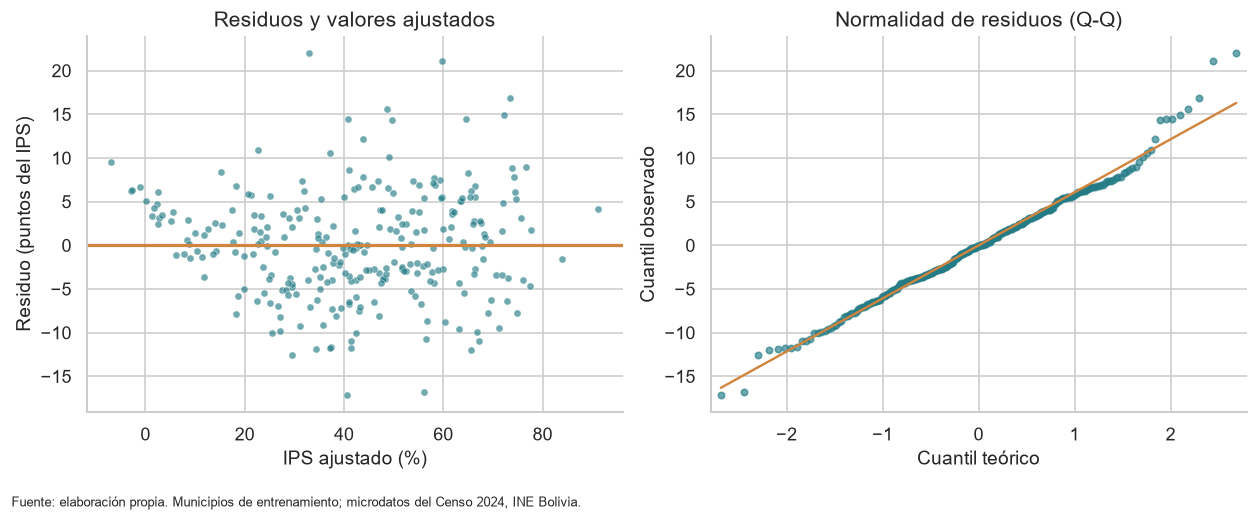

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(modelo_reducido.fittedvalues, modelo_reducido.resid, s=20, alpha=0.65, color=COLOR, edgecolor="white", linewidth=0.4)
axes[0].axhline(0, color=REFERENCIA, linewidth=2)
axes[0].set(title="Residuos y valores ajustados", xlabel="IPS ajustado (%)", ylabel="Residuo (puntos del IPS)")
sm.qqplot(modelo_reducido.resid, line="s", ax=axes[1], markersize=4, alpha=0.65, markerfacecolor=COLOR, markeredgecolor=COLOR)
axes[1].lines[-1].set_color(REFERENCIA)
axes[1].set(title="Normalidad de residuos (Q-Q)", xlabel="Cuantil teórico", ylabel="Cuantil observado")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Fuente: elaboración propia. Municipios de entrenamiento; microdatos del Censo 2024, INE Bolivia.", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Interpretación:** se rechazan las cuatro hipótesis nulas.

- **Normalidad:** en el gráfico Q-Q los residuos siguen la línea en casi todo el rango y se separan en los extremos, sobre todo con algunos residuos positivos grandes.
- **Homocedasticidad:** la dispersión de los residuos no es constante. Es menor cuando el IPS ajustado es bajo, algo esperable en un porcentaje que no puede bajar de 0.
- **Forma lineal:** RESET indica que falta curvatura. Con IPS ajustado bajo, los residuos son casi todos positivos, y algunos valores ajustados incluso son negativos.
- **Autocorrelación:** municipios cercanos tienen errores parecidos (Durbin-Watson 1,44), lo que hace que los p-valores clásicos puedan ser demasiado optimistas.

Las predicciones siguen siendo utilizables, pero los p-valores clásicos no deben tomarse al pie de la letra. Por eso se prueba una transformación en 4.4 y se usan errores robustos en 4.5.

## 4.4. Transformación de variables

El IPS es un porcentaje acotado. Una recta puede predecir valores menores a 0 o mayores a 100, y ese límite explica parte de la curvatura y de la varianza desigual. Por eso se usa la **transformación logit**, en lugar del logaritmo simple: $logit(IPS) = \ln\left(\frac{IPS/100}{1 - IPS/100}\right)$. Las predicciones se devuelven a porcentaje con la función inversa, de modo que siempre quedan entre 0 y 100.

In [20]:
# misma selección de variables, con la respuesta transformada
modelo_logit = sm.OLS(logit(y_train), x_train[["const"] + variables]).fit()
print(modelo_logit.summary())

p_supuestos_logit, dw_logit = pruebas_supuestos(modelo_logit)
display(pd.DataFrame({"Sin transformar": p_supuestos_nivel, "Con logit": p_supuestos_logit}).round(5))
print(f"Durbin-Watson | sin transformar: {dw_nivel:.3f} | con logit: {dw_logit:.3f}")

                            OLS Regression Results                            
Dep. Variable:                    ips   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.918
Method:                 Least Squares   F-statistic:                     510.1
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.16e-143
Time:                        17:05:21   Log-Likelihood:                -65.265
No. Observations:                 274   AIC:                             144.5
Df Residuals:                     267   BIC:                             169.8
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

,Sin transformar,Con logit
Jarque-Bera (normalidad),0.00378,0.00022
Breusch-Pagan (homocedasticidad),0.00001,0.00055
RESET (forma lineal),0.00001,0.01583
Breusch-Godfrey (autocorrelación),0.00000,0.00821


Durbin-Watson | sin transformar: 1.437 | con logit: 1.683


**Interpretación:** la transformación mejora el modelo sin resolverlo del todo. Los p-valores suben en homocedasticidad, forma lineal y autocorrelación (Durbin-Watson de 1,44 a 1,68), pero siguen por debajo de 0,05; la normalidad no mejora. El AIC y el R² de esta tabla no se comparan directamente con los del modelo sin transformar, porque la respuesta está en otra escala. La comparación justa es en puntos del IPS, y se hace a continuación.

## 4.5. Selección y evaluación del modelo

Los candidatos se comparan con **validación cruzada de 5 particiones dentro de entrenamiento**, con el RMSE en puntos del IPS. Gana el menor RMSE; una diferencia de hasta 0,10 puntos se considera empate y favorece al modelo sin transformar y con menos variables.

Las variables del modelo reducido se eligieron con todo el entrenamiento, por lo que esta validación es algo optimista para ese modelo. Sirve para comparar candidatos, y la evaluación final queda a cargo de prueba.

In [21]:
# validación cruzada de 5 particiones dentro de entrenamiento; prueba no interviene
def rmse_validacion(columnas, transformar):
    errores = []
    particiones = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for ajuste_idx, val_idx in particiones.split(x_train):
        x_ajuste = x_train.iloc[ajuste_idx][["const"] + columnas]
        x_val = x_train.iloc[val_idx][["const"] + columnas]
        y_ajuste, y_val = y_train.iloc[ajuste_idx], y_train.iloc[val_idx]
        if transformar:
            pred = logit_inversa(sm.OLS(logit(y_ajuste), x_ajuste).fit().predict(x_val))
        else:
            pred = sm.OLS(y_ajuste, x_ajuste).fit().predict(x_val)
        errores.append(rmse(y_val, pred))
    return np.mean(errores), np.std(errores)

candidatos = [("Simple", [variable_simple], False),
              ("Múltiple completo", list(predictoras), False),
              ("Múltiple reducido", variables, False),
              ("Múltiple reducido con logit", variables, True)]
filas = []
for nombre, columnas, transformar in candidatos:
    media, desviacion = rmse_validacion(columnas, transformar)
    filas.append({"Modelo": nombre, "Variables": len(columnas), "RMSE validación": media, "Desv. entre particiones": desviacion})
comparacion = pd.DataFrame(filas).set_index("Modelo")
display(comparacion.round(3))

# gana el menor RMSE; un empate favorece al modelo sin transformar y con menos variables
minimo = comparacion["RMSE validación"].min()
empatados = comparacion[comparacion["RMSE validación"] <= minimo + TOLERANCIA_RMSE]
sin_logit = [m for m in empatados.index if "logit" not in m]
nombre_final = (empatados.loc[sin_logit, "Variables"].idxmin() if sin_logit else empatados.index[0])
print("Modelo seleccionado:", nombre_final)

,Variables,RMSE validación,Desv. entre particiones
Modelo,,,
Simple,1,9.696,1.482
Múltiple completo,10,6.340,0.688
Múltiple reducido,6,6.315,0.668
Múltiple reducido con logit,6,6.199,0.734


Modelo seleccionado: Múltiple reducido con logit


**Interpretación:** pasar de una variable a varias reduce claramente el error (de 9,70 a cerca de 6,3 puntos). Retirar cuatro variables no lo empeora. La ventaja del logit (6,20 frente a 6,32) supera la tolerancia por muy poco y es pequeña frente a la variación entre particiones (cerca de 0,7), así que **no es una mejora concluyente de la predicción**. Aun así, es la opción que la regla selecciona, y además respeta el rango de 0 a 100 y mejora los supuestos.

**Coeficientes del modelo final.** El coeficiente está en escala logit. La columna de efecto medio lo traduce a puntos del IPS, promediando sobre los municipios de entrenamiento, porque en este modelo el efecto cambia según el nivel de IPS. Dado que se rechazaron los supuestos, se agregan dos p-valores más exigentes: el robusto HC3 frente a varianza desigual, y el agrupado por provincia frente a errores parecidos entre municipios cercanos.

In [22]:
usa_logit = "logit" in nombre_final
modelo_final = modelo_logit if usa_logit else modelo_reducido
columnas_final = ["const"] + variables
assert nombre_final in ("Múltiple reducido", "Múltiple reducido con logit")

# errores estándar robustos: heterocedasticidad (HC3) y dependencia dentro de cada provincia
robusto = modelo_final.get_robustcov_results(cov_type="HC3")
respuesta_train = logit(y_train) if usa_logit else y_train
por_provincia = sm.OLS(respuesta_train, x_train[columnas_final]).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(municipios.loc[x_train.index, "provincia"])[0]})

# efecto aproximado sobre el IPS, en puntos, por cada punto adicional de la variable
ajustado = logit_inversa(modelo_final.fittedvalues) if usa_logit else modelo_final.fittedvalues
factor = (ajustado/100 * (1 - ajustado/100)).mean() * 100 if usa_logit else 1.0
coeficientes = pd.DataFrame({
    "Coeficiente": modelo_final.params,
    "Efecto medio en puntos de IPS": modelo_final.params * factor,
    "p clásico": modelo_final.pvalues,
    "p robusto HC3": pd.Series(robusto.pvalues, index=columnas_final),
    "p por provincia": por_provincia.pvalues,
}).drop("const").sort_values("Efecto medio en puntos de IPS", key=np.abs, ascending=False)
display(coeficientes.round(4))

,Coeficiente,Efecto medio en puntos de IPS,p clásico,p robusto HC3,p por provincia
pct_hasta_un_dormitorio,0.0283,0.5656,0.0000,0.0000,0.0000
pct_alquiler_anticretico,-0.0179,-0.3585,0.0001,0.0004,0.0035
pct_piso_tierra,0.0139,0.2776,0.0000,0.0000,0.0000
pct_basura_sin_servicio,0.0064,0.1287,0.0000,0.0002,0.0001
pct_techo_paja,0.0063,0.1257,0.0005,0.0299,0.0229
pct_pared_no_ladrillo,0.0059,0.1185,0.0004,0.0028,0.0061


**Interpretación**, siempre manteniendo constantes las demás variables:

- **`pct_hasta_un_dormitorio` (+0,57):** cada punto porcentual adicional de viviendas con cero o un dormitorio se asocia con 0,57 puntos más de IPS, en promedio. Es la mayor magnitud.
- **`pct_alquiler_anticretico` (-0,36):** es la única asociación negativa. Probablemente refleja mercados de vivienda más urbanos y con más servicios, no un efecto del contrato de alquiler.
- **`pct_piso_tierra` (+0,28):** su efecto baja frente al de la regresión simple (+0,82), porque ahora comparte lo que explica con variables correlacionadas.
- **`pct_basura_sin_servicio`, `pct_techo_paja` y `pct_pared_no_ladrillo` (+0,12 a +0,13):** asociaciones positivas más pequeñas.

Las seis variables siguen siendo significativas con las tres formas de calcular el p-valor. La más débil es `pct_techo_paja` (0,030 con HC3 y 0,023 por provincia). Estas magnitudes dependen de la escala de cada variable y **no son efectos causales**: indican qué municipios tienden a tener más carencias, no qué pasaría al intervenir.

**Evaluación en prueba.** Es el único uso del conjunto reservado, con el modelo ya elegido.

In [23]:
# Predicciones sobre prueba: se usa una sola vez, con el modelo ya elegido
def predecir(modelo, datos, transformado):
    pred = modelo.predict(datos)
    return logit_inversa(pred) if transformado else pred

y_pred = predecir(modelo_final, x_test[columnas_final], usa_logit)
y_pred_train = predecir(modelo_final, x_train[columnas_final], usa_logit)
y_pred_simple = modelo_simple.predict(x_test)
y_pred_media = pd.Series(y_train.mean(), index=y_test.index)  # referencia sin variables

def metricas(nombre, real, pred):
    return {"Modelo": nombre, "MSE": mean_squared_error(real, pred), "RMSE": rmse(real, pred),
            "MAE": mean_absolute_error(real, pred), "R²": r2_score(real, pred)}

evaluacion = pd.DataFrame([
    metricas("Final, entrenamiento", y_train, y_pred_train),
    metricas("Final, prueba", y_test, y_pred),
    metricas("Simple, prueba", y_test, y_pred_simple),
    metricas("Promedio de entrenamiento, prueba", y_test, y_pred_media),
]).set_index("Modelo")
display(evaluacion.round(3))

,MSE,RMSE,MAE,R²
Modelo,,,,
"Final, entrenamiento",35.777,5.981,4.547,0.919
"Final, prueba",49.774,7.055,5.256,0.898
"Simple, prueba",61.755,7.858,6.023,0.873
"Promedio de entrenamiento, prueba",487.338,22.076,19.028,-0.000


In [24]:
display(Markdown(
    f"En los **{len(y_test)} municipios de prueba**, el modelo final obtuvo **R²={evaluacion.loc['Final, prueba','R²']:.3f}**, "
    f"**RMSE={evaluacion.loc['Final, prueba','RMSE']:.2f}** y **MAE={evaluacion.loc['Final, prueba','MAE']:.2f}** puntos del IPS. "
    f"Predecir siempre el promedio de entrenamiento daría un RMSE de **{evaluacion.loc['Promedio de entrenamiento, prueba','RMSE']:.2f}**, "
    f"y la regresión simple, de **{evaluacion.loc['Simple, prueba','RMSE']:.2f}**. "
    f"El RMSE pasa de **{evaluacion.loc['Final, entrenamiento','RMSE']:.2f}** en entrenamiento a "
    f"**{evaluacion.loc['Final, prueba','RMSE']:.2f}** en prueba; esa diferencia es esperable y no alcanza para hablar de un sobreajuste marcado."
))

En los **69 municipios de prueba**, el modelo final obtuvo **R²=0.898**, **RMSE=7.06** y **MAE=5.26** puntos del IPS. Predecir siempre el promedio de entrenamiento daría un RMSE de **22.08**, y la regresión simple, de **7.86**. El RMSE pasa de **5.98** en entrenamiento a **7.06** en prueba; esa diferencia es esperable y no alcanza para hablar de un sobreajuste marcado.

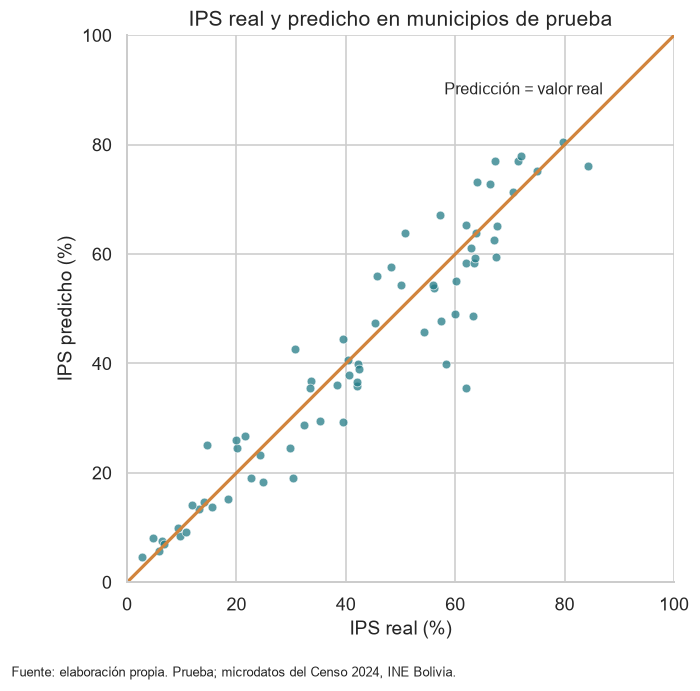

In [25]:
# Valores reales y predicciones: sobre la línea, la predicción coincide con el valor real
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, y_pred, s=30, alpha=0.75, color=COLOR, edgecolor="white", linewidth=0.5)
ax.plot([0, 100], [0, 100], color=REFERENCIA, linewidth=2)
ax.annotate("Predicción = valor real", (90, 90), xytext=(-10, 0), textcoords="offset points", ha="right", va="center")
ax.set(title="IPS real y predicho en municipios de prueba", xlabel="IPS real (%)", ylabel="IPS predicho (%)",
       xlim=(0, 100), ylim=(0, 100), aspect="equal")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Fuente: elaboración propia. Prueba; microdatos del Censo 2024, INE Bolivia.", fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Interpretación:** los puntos siguen de cerca la línea de referencia en todo el rango y no se observa un sesgo evidente. Las mayores diferencias son pocos municipios por encima de la línea o por debajo de ella, que se revisan a continuación.

**¿Dónde falla más?** Se compara el error según la cobertura, porque el IPS de un municipio con baja cobertura se calcula con una parte menor de sus viviendas.

In [26]:
# ¿dónde se equivoca más? Errores de prueba según la cobertura del objetivo
errores_prueba = municipios.loc[y_test.index, ["departamento", "n_viviendas", "cobertura", "ips"]].assign(
    ips_predicho=y_pred, error=lambda t: t["ips"] - t["ips_predicho"])
tramo = np.where(errores_prueba["cobertura"] >= 50, "Cobertura de 50 % o más", "Cobertura menor a 50 %")
por_cobertura = pd.DataFrame([
    {"Tramo": nombre, "Municipios": len(t), "RMSE": rmse(t["ips"], t["ips_predicho"]), "R²": r2_score(t["ips"], t["ips_predicho"])}
    for nombre, t in errores_prueba.groupby(tramo)]).set_index("Tramo")
display(por_cobertura.round(3))
# mayores diferencias: el IPS real supera (+) o queda bajo (-) lo esperado por el modelo
display(errores_prueba.reindex(errores_prueba["error"].abs().sort_values(ascending=False).index).head(6).round(1))

,Municipios,RMSE,R²
Tramo,,,
Cobertura de 50 % o más,55,5.566,0.942
Cobertura menor a 50 %,14,11.118,0.588


,departamento,n_viviendas,cobertura,ips,ips_predicho,error
municipio,,,,,,
090501,Pando,126,25.8,61.9,35.5,26.4
080402,Beni,606,41.6,58.3,40.0,18.3
021703,La Paz,990,67.2,63.2,48.7,14.6
080602,Beni,2272,43.1,50.9,63.8,-12.9
031402,Cochabamba,1523,46.7,30.7,42.6,-11.9
070903,Santa Cruz,2238,51.9,30.3,19.1,11.2


**Interpretación:** el error es el doble en los municipios con cobertura menor a 50 % (RMSE 11,12 frente a 5,57). Son solo 14 municipios de prueba, pero el resultado advierte que el modelo y el propio IPS son menos confiables allí, y que esas viviendas pueden no ser representativas de su municipio.

La mayor diferencia es la del municipio `090501` de Pando: IPS real de 61,9 % y 35,5 % predicho, con solo 126 viviendas clasificables y 25,8 % de cobertura. Una diferencia así **no prueba** una situación excepcional: es un caso para revisar primero en los datos y luego en el territorio.

## 4.6. Validación territorial

Una división aleatoria deja municipios vecinos en entrenamiento y en prueba. Para saber si el modelo sirve en un territorio que no vio, se entrena con ocho departamentos y se predicen los municipios del noveno, y así con cada uno. Se mantienen las variables ya elegidas, lo que hace esta prueba levemente optimista, porque se seleccionaron con municipios de todos los departamentos. En `Error medio`, un valor positivo indica que el IPS real superó lo predicho.

In [27]:
# dejar un departamento fuera: se entrena con ocho y se predicen los municipios del noveno
X_final = X[columnas_final]
predicciones_dep = pd.Series(index=X_final.index, dtype=float)
for ajuste_idx, val_idx in LeaveOneGroupOut().split(X_final, y, groups=municipios["departamento"]):
    respuesta = logit(y.iloc[ajuste_idx]) if usa_logit else y.iloc[ajuste_idx]
    ajuste_dep = sm.OLS(respuesta, X_final.iloc[ajuste_idx]).fit()
    predicciones_dep.iloc[val_idx] = predecir(ajuste_dep, X_final.iloc[val_idx], usa_logit)

territorial = pd.DataFrame([
    {"Departamento fuera": dep, "Municipios": len(t), "RMSE": rmse(y.loc[t.index], predicciones_dep.loc[t.index]),
     "Error medio": (y.loc[t.index] - predicciones_dep.loc[t.index]).mean()}
    for dep, t in municipios.groupby("departamento")]).sort_values("RMSE", ascending=False)
display(territorial.round(2))
r2_territorial = r2_score(y, predicciones_dep)
rmse_territorial = rmse(y, predicciones_dep)
print(f"Conjunto de los 343 municipios | R²: {r2_territorial:.3f} | RMSE: {rmse_territorial:.2f} puntos")

,Departamento fuera,Municipios,RMSE,Error medio
5,Pando,15,15.10,12.42
3,La Paz,87,6.99,3.43
6,Potosí,42,6.77,-2.71
4,Oruro,35,6.26,-4.07
0,Beni,20,6.24,0.81
7,Santa Cruz,56,6.22,-1.02
8,Tarija,11,6.07,0.45
2,Cochabamba,48,5.81,-1.67
1,Chuquisaca,29,5.70,1.98


Conjunto de los 343 municipios | R²: 0.890 | RMSE: 7.02 puntos


**Interpretación:** el modelo se sostiene bastante bien al cambiar de departamento (RMSE conjunto 7,02), con errores de 5,70 a 6,99 puntos en ocho de los nueve. **Pando es la excepción**: RMSE de 15,10 y una subestimación media de 12,42 puntos. Allí las mismas características de la vivienda se asocian con un IPS mayor que en el resto del país, de modo que **este modelo no debe aplicarse a Pando sin ajustarlo**. Con 15 municipios, este resultado no permite identificar la causa.

# 5. RESULTADOS

## 5.1. Limitaciones

- **Municipios, no viviendas ni personas:** una asociación entre municipios no implica la misma relación dentro de cada vivienda (falacia ecológica). Las métricas no son comparables con las de los clasificadores anteriores, que trabajan a nivel de vivienda.
- **Sin causalidad:** es un corte transversal de un solo censo; las variables describen contextos que pueden estar ligados a factores no medidos, como el ingreso o la inversión pública.
- **Supuestos:** se rechazan incluso con logit. Los p-valores robustos ayudan, pero son aproximados, y la selección por pasos tiende a dar p-valores optimistas en las variables que quedan.
- **Cobertura:** 27,28 % de las viviendas analíticas no tiene clase, y la cobertura municipal va de 21,14 % a 95,86 %. Si las viviendas excluidas difieren de las incluidas, el IPS municipal puede estar sesgado.
- **Peso igual por municipio:** se favorece la lectura territorial, pero un municipio pequeño, con un IPS más ruidoso, influye tanto como una capital.
- **Prueba pequeña:** 69 municipios. El R² de prueba depende de qué municipios caigan en esa partición, por lo que conviene leerlo junto con la validación territorial.
- **Retransformación:** al volver desde el logit, la predicción se acerca más a una mediana que a un promedio. Es un sesgo pequeño, que no se corrigió.

## 5.2. Conclusiones

In [28]:
principal = coeficientes.index[0]
display(Markdown(
    f"Se resumieron **{int(municipios['n_viviendas'].sum()):,} viviendas clasificables** en **{len(municipios)} municipios**. "
    f"El modelo seleccionado fue **{nombre_final.lower()}**, con **{len(variables)} variables**. En prueba explicó "
    f"**{100*evaluacion.loc['Final, prueba','R²']:.1f} %** de la variación del IPS municipal, con un error típico (RMSE) de "
    f"**{evaluacion.loc['Final, prueba','RMSE']:.2f} puntos**. Al predecir cada departamento sin haberlo usado en el ajuste, "
    f"el R² conjunto fue **{r2_territorial:.3f}** y el RMSE **{rmse_territorial:.2f} puntos**. "
    f"La asociación de mayor magnitud fue la de `{principal}`: **{coeficientes.loc[principal,'Efecto medio en puntos de IPS']:+.2f} puntos** "
    "de IPS en promedio por cada punto porcentual adicional, manteniendo constantes las demás variables. "
    "El modelo sirve para describir y para priorizar la revisión de municipios; no demuestra que cambiar esas características reduzca las carencias."
))

Se resumieron **2,635,157 viviendas clasificables** en **343 municipios**. El modelo seleccionado fue **múltiple reducido con logit**, con **6 variables**. En prueba explicó **89.8 %** de la variación del IPS municipal, con un error típico (RMSE) de **7.06 puntos**. Al predecir cada departamento sin haberlo usado en el ajuste, el R² conjunto fue **0.890** y el RMSE **7.02 puntos**. La asociación de mayor magnitud fue la de `pct_hasta_un_dormitorio`: **+0.57 puntos** de IPS en promedio por cada punto porcentual adicional, manteniendo constantes las demás variables. El modelo sirve para describir y para priorizar la revisión de municipios; no demuestra que cambiar esas características reduzca las carencias.

**Trabajo posterior:** ajustar un modelo ponderado por número de viviendas, revisar por qué baja la cobertura en algunos municipios y estudiar Pando por separado.

## 5.3. Fuente de los datos

**Instituto Nacional de Estadística (INE) de Bolivia.** Microdatos oficiales del **Censo de Población y Vivienda 2024**, archivo `Vivienda_CPV-2024.csv`; categorías contrastadas con `data/Diccionario de variables CPV 2024.xlsx`. Las reglas de población y de carencia se reproducen de `entendimiento de datos.ipynb`. El IPS, las variables municipales, las tablas, las figuras y los modelos son elaboración propia.